In [1]:
import pandas as pd 
import numpy as np 

In [2]:
df = pd.read_csv("breast-cancer-wisconsin.data",header=None) #tuve que ocupar None porque mi data no contiene el encabezado 

In [3]:
df.head()

,0,1,2,3,4,5,6,7,8,9,10
0,1000025,5,1,1,1,2,1,3,1,1,2
1,1002945,5,4,4,5,7,10,3,2,1,2
2,1015425,3,1,1,1,2,2,3,1,1,2
3,1016277,6,8,8,1,3,4,3,7,1,2
4,1017023,4,1,1,3,2,1,3,1,1,2


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 699 entries, 0 to 698
Data columns (total 11 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   0       699 non-null    int64 
 1   1       699 non-null    int64 
 2   2       699 non-null    int64 
 3   3       699 non-null    int64 
 4   4       699 non-null    int64 
 5   5       699 non-null    int64 
 6   6       699 non-null    object
 7   7       699 non-null    int64 
 8   8       699 non-null    int64 
 9   9       699 non-null    int64 
 10  10      699 non-null    int64 
dtypes: int64(10), object(1)
memory usage: 60.2+ KB


In [5]:
df.shape

(699, 11)

In [6]:
df=df.rename(columns={0:"Sample code number",1:"Clump Thickness",2:"Uniformity of Cell Size",3:"Uniformity of Cell Shape",4:"Marginal Adhesion",5:"Single Epithelial Cell Size",6:"Bare Nuclei",7:"Bland Chromatin",8:"Normal Nucleoli",9:"Mitoses",10:"Class"})

In [7]:
df.head()

,Sample code number,Clump Thickness,Uniformity of Cell Size,Uniformity of Cell Shape,Marginal Adhesion,Single Epithelial Cell Size,Bare Nuclei,Bland Chromatin,Normal Nucleoli,Mitoses,Class
0,1000025,5,1,1,1,2,1,3,1,1,2
1,1002945,5,4,4,5,7,10,3,2,1,2
2,1015425,3,1,1,1,2,2,3,1,1,2
3,1016277,6,8,8,1,3,4,3,7,1,2
4,1017023,4,1,1,3,2,1,3,1,1,2


tuve que ejecutar rename ya que mi data venia sin encabezado, tuve que agregar los titulos desde datadiccionary 

In [8]:
df.isnull().sum()

Sample code number             0
Clump Thickness                0
Uniformity of Cell Size        0
Uniformity of Cell Shape       0
Marginal Adhesion              0
Single Epithelial Cell Size    0
Bare Nuclei                    0
Bland Chromatin                0
Normal Nucleoli                0
Mitoses                        0
Class                          0
dtype: int64

In [9]:
df["Sample code number"].unique()

array([ 1000025,  1002945,  1015425,  1016277,  1017023,  1017122,
        1018099,  1018561,  1033078,  1035283,  1036172,  1041801,
        1043999,  1044572,  1047630,  1048672,  1049815,  1050670,
        1050718,  1054590,  1054593,  1056784,  1057013,  1059552,
        1065726,  1066373,  1066979,  1067444,  1070935,  1071760,
        1072179,  1074610,  1075123,  1079304,  1080185,  1081791,
        1084584,  1091262,  1096800,  1099510,  1100524,  1102573,
        1103608,  1103722,  1105257,  1105524,  1106095,  1106829,
        1108370,  1108449,  1110102,  1110503,  1110524,  1111249,
        1112209,  1113038,  1113483,  1113906,  1115282,  1115293,
        1116116,  1116132,  1116192,  1116998,  1117152,  1118039,
        1120559,  1121732,  1121919,  1123061,  1124651,  1125035,
        1126417,  1131294,  1132347,  1133041,  1133136,  1136142,
        1137156,  1143978,  1147044,  1147699,  1147748,  1148278,
        1148873,  1152331,  1155546,  1156272,  1156948,  1157

In [10]:
df["Clump Thickness"].unique()

array([ 5,  3,  6,  4,  8,  1,  2,  7, 10,  9], dtype=int64)

In [11]:
df["Uniformity of Cell Size"].unique()

array([ 1,  4,  8, 10,  2,  3,  7,  5,  6,  9], dtype=int64)

In [12]:
df["Uniformity of Cell Shape"].unique()

array([ 1,  4,  8, 10,  2,  3,  5,  6,  7,  9], dtype=int64)

In [13]:
df["Marginal Adhesion"].unique()

array([ 1,  5,  3,  8, 10,  4,  6,  2,  9,  7], dtype=int64)

In [14]:
df["Single Epithelial Cell Size"].unique()

array([ 2,  7,  3,  1,  6,  4,  5,  8, 10,  9], dtype=int64)

In [15]:
df["Bare Nuclei"].unique()

array(['1', '10', '2', '4', '3', '9', '7', '?', '5', '8', '6'],
      dtype=object)

In [16]:
df["Bare Nuclei"].value_counts()

Bare Nuclei
1     402
10    132
2      30
5      30
3      28
8      21
4      19
?      16
9       9
7       8
6       4
Name: count, dtype: int64

In [17]:
faltantes = df["Bare Nuclei"]=="?" #debo conocer en que rows tengo dato faltante y segun mi feature categorical se si es  Benign: 458 (65.5%) Malignant: 241 (34.5%
df.loc[faltantes,"Class"]

23     4
40     2
139    2
145    2
158    2
164    2
235    2
249    2
275    2
292    4
294    2
297    2
315    2
321    2
411    2
617    2
Name: Class, dtype: int64

#debo comparar la cantidad de casos malignos entre los 699 filas originales y las 683 que quedarian si descarto esa fila. aunque la mayoria sea benigno.*lo que me ayudara a justificar la decision, es cuantos puntos porcentuales cambia la proporcion de malignos* 

In [18]:
df.loc[faltantes, "Class"].value_counts(normalize = True)*100

Class
2    87.5
4    12.5
Name: proportion, dtype: float64

In [19]:
#before 699 filas originales 
df["Class"].value_counts(normalize=True)*100

Class
2    65.522175
4    34.477825
Name: proportion, dtype: float64

In [20]:
df.loc[~faltantes,"Class"].value_counts(normalize=True)*100

Class
2    65.007321
4    34.992679
Name: proportion, dtype: float64

como podemos observar eliminar las filas es una decision razonable, representa solo el 2.3% de los registros y su exclusion cambia muy poco la proporcion de la clase. los casos malignos pasa de 34,48% a 34,99%

In [21]:
df["Bare Nuclei"] = df ["Bare Nuclei"].replace("?", np.nan)

In [22]:
df = df.dropna()
df.count()

Sample code number             683
Clump Thickness                683
Uniformity of Cell Size        683
Uniformity of Cell Shape       683
Marginal Adhesion              683
Single Epithelial Cell Size    683
Bare Nuclei                    683
Bland Chromatin                683
Normal Nucleoli                683
Mitoses                        683
Class                          683
dtype: int64

In [23]:
df.isnull().sum()

Sample code number             0
Clump Thickness                0
Uniformity of Cell Size        0
Uniformity of Cell Shape       0
Marginal Adhesion              0
Single Epithelial Cell Size    0
Bare Nuclei                    0
Bland Chromatin                0
Normal Nucleoli                0
Mitoses                        0
Class                          0
dtype: int64

In [24]:
df.shape

(683, 11)

luego de analizar la data decidi eliminar las filas de los datos faltantes para trabajar 

In [25]:
df["Bare Nuclei"].unique()

array(['1', '10', '2', '4', '3', '9', '7', '5', '8', '6'], dtype=object)

In [26]:
df["Bland Chromatin"].unique()

array([ 3,  9,  1,  2,  4,  5,  7,  8,  6, 10], dtype=int64)

In [27]:
df["Normal Nucleoli"].unique()

array([ 1,  2,  7,  4,  5,  3, 10,  6,  9,  8], dtype=int64)

In [28]:
df["Mitoses"].unique()

array([ 1,  5,  4,  2,  3,  7, 10,  8,  6], dtype=int64)

In [29]:
df["Class"].unique()

array([2, 4], dtype=int64)

In [30]:
df.head()

,Sample code number,Clump Thickness,Uniformity of Cell Size,Uniformity of Cell Shape,Marginal Adhesion,Single Epithelial Cell Size,Bare Nuclei,Bland Chromatin,Normal Nucleoli,Mitoses,Class
0,1000025,5,1,1,1,2,1,3,1,1,2
1,1002945,5,4,4,5,7,10,3,2,1,2
2,1015425,3,1,1,1,2,2,3,1,1,2
3,1016277,6,8,8,1,3,4,3,7,1,2
4,1017023,4,1,1,3,2,1,3,1,1,2


In [32]:
df_new =df.drop(columns=["Sample code number"])

decido eliminar sample code number porque no tiene ninguna importancia en mi data. 

In [33]:
df_new.head()

,Clump Thickness,Uniformity of Cell Size,Uniformity of Cell Shape,Marginal Adhesion,Single Epithelial Cell Size,Bare Nuclei,Bland Chromatin,Normal Nucleoli,Mitoses,Class
0,5,1,1,1,2,1,3,1,1,2
1,5,4,4,5,7,10,3,2,1,2
2,3,1,1,1,2,2,3,1,1,2
3,6,8,8,1,3,4,3,7,1,2
4,4,1,1,3,2,1,3,1,1,2


In [36]:
label = df[["Class"]]

In [37]:
X = df_new           # Features (independent variables) from the Cancer dataset

y = label            # Target variable (Class) for the prediction

In [38]:
label.head()

,Class
0,2
1,2
2,2
3,2
4,2


In [40]:
y.value_counts()

Class
2        444
4        239
Name: count, dtype: int64

In [42]:
from sklearn.tree import DecisionTreeClassifier, plot_tree       # Import Decision Tree Classifier and plot_tree 
from sklearn.model_selection import train_test_split             # Import train_test_split function
from sklearn import metrics                                      # Import scikit-learn metrics module for accuracy calculation
from sklearn import tree
import matplotlib.pyplot as plt

## Splitting Data 

In [52]:
# Split dataset in features and target variable
feature_cols = ['Clump Thickness', 'Uniformity of Cell Size', 'Uniformity of Cell Shape', 'Marginal Adhesion', 'Single Epithelial Cell Size', 'Bare Nuclei', 'Bland Chromatin', 'Mitoses']
X = df[feature_cols]               # Features of the dataset
y = df.Class                       # Target variable of the dataset

# X = pima.iloc[:, :-1]              # All rows, all columns except the last
# y = pima.iloc[:, -1]               # All rows, only the last column

# X = pima.iloc[:, 0:8]
# y = pima.iloc[:, 8]

# Display the X and y arrays
print(X, y)

     Clump Thickness  Uniformity of Cell Size  Uniformity of Cell Shape  \
0                  5                        1                         1   
1                  5                        4                         4   
2                  3                        1                         1   
3                  6                        8                         8   
4                  4                        1                         1   
..               ...                      ...                       ...   
694                3                        1                         1   
695                2                        1                         1   
696                5                       10                        10   
697                4                        8                         6   
698                4                        8                         8   

     Marginal Adhesion  Single Epithelial Cell Size Bare Nuclei  \
0                    1          

In [53]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.3, random_state = 1) # 70% training and 30% test

In [54]:
 #Create Decision Tree classifer object
clf = DecisionTreeClassifier(criterion = 'gini', max_depth = 3, random_state = 0)

# Train Decision Tree Classifer
clf = clf.fit(X_train, y_train)

#Predict the response for test dataset
y_pred = clf.predict(X_test)

In [55]:
# Example: y_pred is numpy array, y_test is pandas Series
# (just using your example variables)
# y_pred = np.array([...])
# y_test = df['label']   # for instance

# Combine into DataFrame
results = pd.DataFrame({
    "y_test (True)": y_test.reset_index(drop=True),  # reset index for alignment
    "y_pred (Predicted)": y_pred
})

# Show first 20 rows for a quick view
print(results.head(20))

# If you also want to check correctness
results["Correct?"] = results["y_test (True)"] == results["y_pred (Predicted)"]

print(results.head(20))

    y_test (True)  y_pred (Predicted)
0               2                   2
1               2                   2
2               2                   2
3               4                   4
4               2                   2
5               4                   4
6               2                   2
7               2                   2
8               4                   4
9               4                   4
10              2                   2
11              2                   2
12              4                   4
13              4                   4
14              2                   2
15              4                   4
16              2                   2
17              2                   4
18              2                   2
19              2                   2
    y_test (True)  y_pred (Predicted)  Correct?
0               2                   2      True
1               2                   2      True
2               2                   2      True
3         

## Evaluating Model

In [56]:
# Model Accuracy, how often is the classifier correct?
print("Accuracy:",metrics.accuracy_score(y_test, y_pred))

# Rounded upto 2 decimal places
print( "Accuracy: {:.2f}".format(metrics.accuracy_score(y_test, y_pred)) )

Accuracy: 0.9560975609756097
Accuracy: 0.96


In [57]:
X.columns.tolist()

['Clump Thickness',
 'Uniformity of Cell Size',
 'Uniformity of Cell Shape',
 'Marginal Adhesion',
 'Single Epithelial Cell Size',
 'Bare Nuclei',
 'Bland Chromatin',
 'Mitoses']

In [59]:
df['Class'].unique().tolist()

[2, 4]

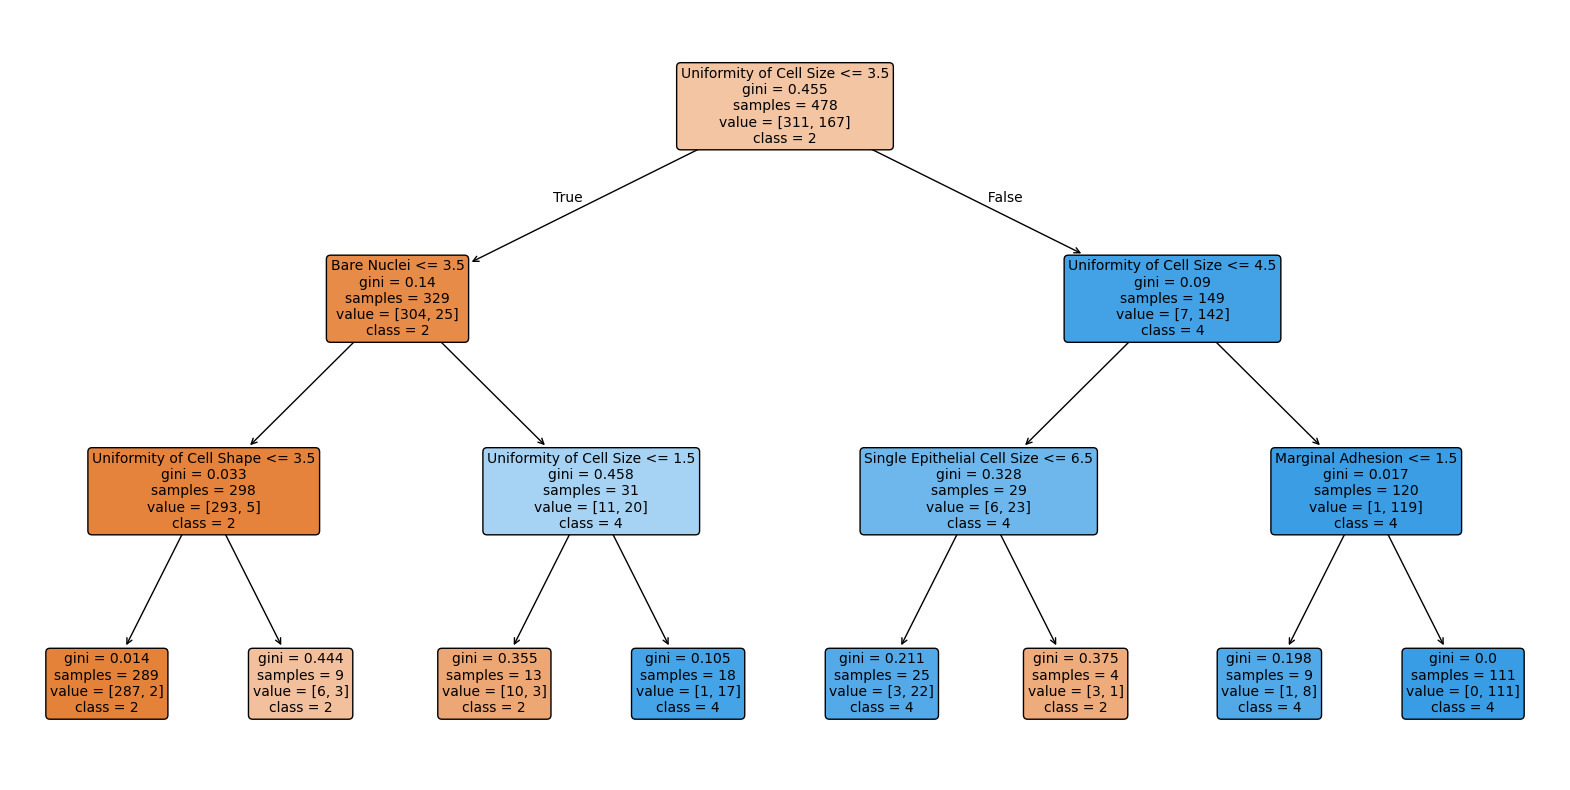

In [61]:
# Plot the Decision Tree
plt.figure(figsize = (20, 10))
plot_tree(clf, filled = True, feature_names = X.columns.tolist(), class_names = [str(label) for label in df['Class'].unique()], 
          rounded = True, fontsize = 10)
plt.show()